# Explain the saved duration model

This notebook loads the saved XGBoost champion and existing feature/split artifacts. SHAP contributions are on the model output scale: log minutes.


In [43]:

from pathlib import Path
import sys, json, warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap

TEAM_DIR = Path.cwd() if (Path.cwd() / 'artifacts' / 'availability_duration_bundle_optuna_mlflow.joblib').is_file() else next(p / 'team' / 'mariam_availability' for p in [Path.cwd(), *Path.cwd().parents] if (p / 'team' / 'mariam_availability' / 'artifacts' / 'availability_duration_bundle_optuna_mlflow.joblib').is_file())
REPO_ROOT = TEAM_DIR.parents[1]
sys.path.insert(0, str(TEAM_DIR))
from src.availability.features import FeatureEncoder, split_by_time

ARTIFACTS = TEAM_DIR / 'artifacts'
REPORTS = TEAM_DIR / 'reports'
FIGURES = REPORTS / 'figures' / 'xai'
FIGURES.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', category=FutureWarning)
print('TASK 8.1 — SHAP SETUP AND CHECKS')
print(f"{'bundle path':24s}: {ARTIFACTS / 'availability_duration_bundle_optuna_mlflow.joblib'}")


TASK 8.1 — SHAP SETUP AND CHECKS
bundle path             : c:\Users\mariam\Desktop\SIC AI\ChargeSentinel-Twin\team\mariam_availability\notebooks\artifacts\availability_duration_bundle_optuna_mlflow.joblib


### Setup and checks
Load the saved bundle, saved feature table, split metadata, and encoder. Recreate validation normal sessions and take a deterministic sample of up to 2,000 rows. Stop if the saved estimator is not XGBoost.


In [44]:
bundle = joblib.load(ARTIFACTS / 'availability_duration_bundle_optuna_mlflow.joblib')
features_all = joblib.load(ARTIFACTS / 'features_all.pkl')
split_config = joblib.load(ARTIFACTS / 'config_split.pkl')
encoder = FeatureEncoder.from_state(bundle['encoder_state'])
model = bundle['model']
if not isinstance(model, xgb.XGBModel):
    raise RuntimeError(f"SHAP notebook stopped: expected XGBoost, found {type(model).__module__}.{type(model).__name__}")
train_frame, validation_frame, test_frame = split_by_time(features_all)
validation_normal = validation_frame.loc[validation_frame['is_abnormal'].eq(0)].copy()
X_validation = encoder.transform(validation_normal)
sample_size = min(2000, len(X_validation))
sample_positions = np.random.RandomState(42).choice(len(X_validation), size=sample_size, replace=False)
X_sample = X_validation.iloc[sample_positions].copy()
y_sample = validation_normal['target_min'].iloc[sample_positions].astype(float).to_numpy()
bundle_version = f"{bundle.get('model_name', 'availability_duration')}@{bundle['data_version'].get('data_sha256_12', 'unknown')}"
print(f"{'model name':24s}: {bundle.get('model_name', type(model).__name__)}")
print(f"{'bundle version':24s}: {bundle_version}")
print(f"{'feature count':24s}: {X_sample.shape[1]}")
print(f"{'validation normal rows':24s}: {len(validation_normal)}")
print(f"{'sample size':24s}: {sample_size}")
print(f"{'train end (exclusive)':24s}: {split_config['TRAIN_END']}")
print(f"{'validation end':24s}: {split_config['VAL_END']}")
assert sample_size > 0
assert list(X_sample.columns) == list(bundle['feature_names'])


model name              : xgboost_default
bundle version          : xgboost_default@e518e9c6d140
feature count           : 22
validation normal rows  : 59752
sample size             : 2000
train end (exclusive)   : 2021-07-01 00:00:00
validation end          : 2021-10-01 00:00:00


Interpretation: the saved estimator and its encoder were loaded without fitting. The sample is drawn only from validation normal sessions, with a fixed random seed for repeatability.


### SHAP values and additivity checks
Use TreeExplainer and compare its values with XGBoost's native `pred_contribs=True` contributions. Check additivity against the raw model margin for every sampled row.


In [45]:
print(' SHAP ADDITIVITY CHECK')

best_iteration = getattr(model, 'best_iteration', None)
explain_booster = model.get_booster()
if best_iteration is not None:
    explain_booster = explain_booster[:int(best_iteration) + 1]
explainer = shap.TreeExplainer(explain_booster)
shap_explanation = explainer(X_sample)
shap_values = np.asarray(shap_explanation.values, dtype=float)
base_values = np.asarray(shap_explanation.base_values, dtype=float).reshape(-1)
dmatrix = xgb.DMatrix(X_sample, feature_names=list(X_sample.columns))
native_contributions = explain_booster.predict(dmatrix, pred_contribs=True)
raw_margin = np.asarray(model.predict(X_sample, output_margin=True), dtype=float)
additivity_error = np.abs(base_values + shap_values.sum(axis=1) - raw_margin)
native_error = np.max(np.abs(shap_values - native_contributions[:, :-1]))
native_base_error = np.max(np.abs(base_values - native_contributions[:, -1]))
print(f"{'max SHAP additivity error':32s}: {additivity_error.max():.8g}")
print(f"{'max native contribution error':32s}: {native_error:.8g}")
print(f"{'max native base-value error':32s}: {native_base_error:.8g}")
assert additivity_error.max() <= 1e-3
assert native_error <= 1e-3
assert native_base_error <= 1e-3


 SHAP ADDITIVITY CHECK
max SHAP additivity error       : 3.5828853e-06
max native contribution error   : 0
max native base-value error     : 0


Interpretation: the printed maximum errors show whether SHAP and XGBoost's native contributions agree on this validation sample. The assertion enforces the requested 1e-3 margin-additivity tolerance.


### Global feature importance
Plot the SHAP beeswarm for the top 15 features and a mean absolute SHAP bar chart. Save the global ranking as a CSV.


SHAP GLOBAL SUMMARY
Top 10 features by mean absolute SHAP (log minutes):
 1. hist_median_normal          : 0.09847610
 2. idle_before_min             : 0.07872634
 3. charger_id_code             : 0.07748807
 4. hour_cos                    : 0.07713822
 5. hour_sin                    : 0.05226287
 6. hist_mean_normal            : 0.04533099
 7. prev_duration_min           : 0.04510251
 8. sessions_before             : 0.04221239
 9. hour                        : 0.02873396
10. location_code               : 0.02435407


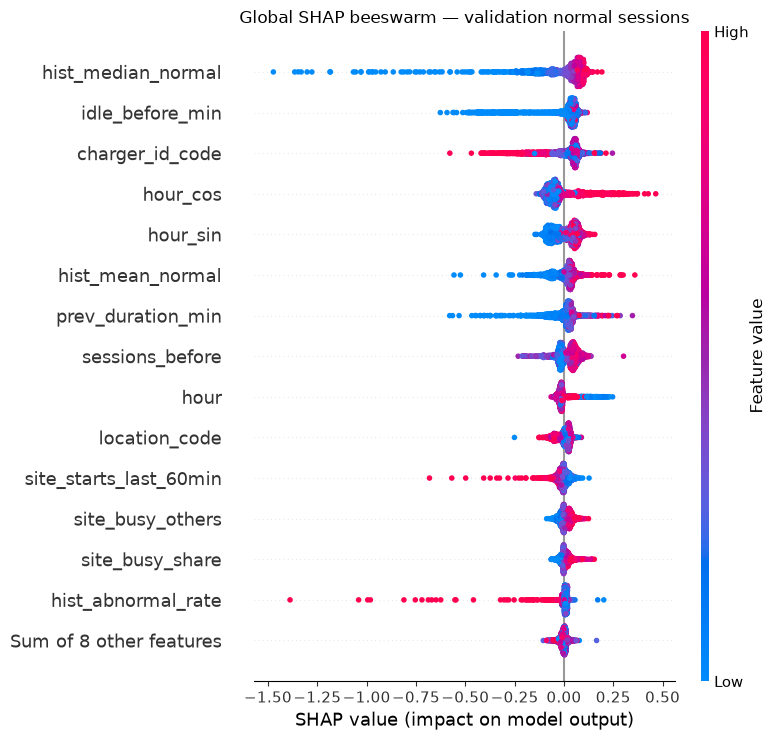

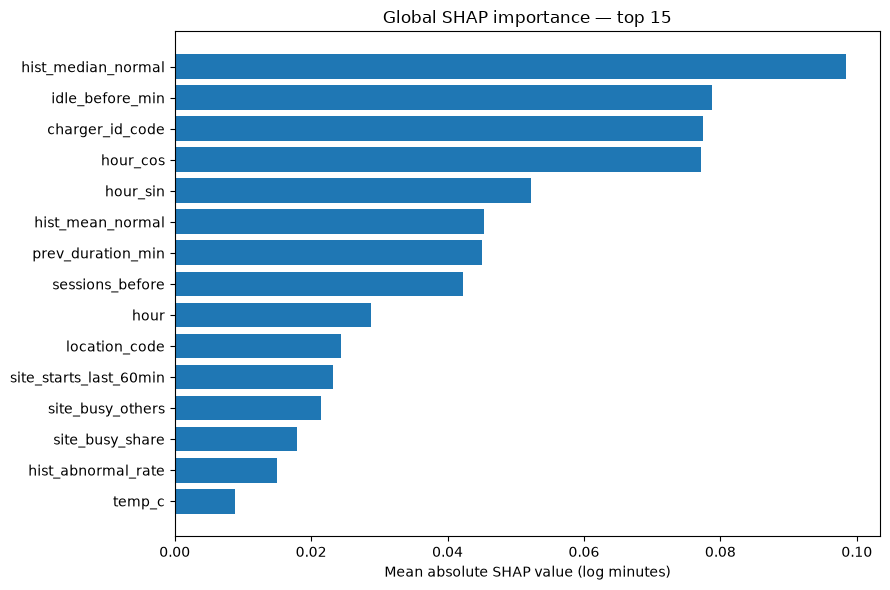

saved importance CSV        : c:\Users\mariam\Desktop\SIC AI\ChargeSentinel-Twin\team\mariam_availability\notebooks\reports\xai_global_importance.csv


In [46]:
print('SHAP GLOBAL SUMMARY')
mean_abs_shap = np.abs(shap_values).mean(axis=0)
global_importance = pd.DataFrame({'feature': X_sample.columns, 'mean_abs_shap': mean_abs_shap}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)
global_importance.to_csv(REPORTS / 'xai_global_importance.csv', index=False)
print('Top 10 features by mean absolute SHAP (log minutes):')
for rank, row in enumerate(global_importance.head(10).itertuples(index=False), start=1):
    print(f"{rank:2d}. {row.feature:28s}: {row.mean_abs_shap:.8f}")
shap.plots.beeswarm(shap_explanation, max_display=15, show=False)
plt.title('Global SHAP beeswarm — validation normal sessions')
plt.tight_layout()
plt.savefig(FIGURES / 'shap_beeswarm_top15.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close()
plt.figure(figsize=(9, 6))
plot_data = global_importance.head(15).sort_values('mean_abs_shap')
plt.barh(plot_data['feature'], plot_data['mean_abs_shap'])
plt.xlabel('Mean absolute SHAP value (log minutes)')
plt.title('Global SHAP importance — top 15')
plt.tight_layout()
plt.savefig(FIGURES / 'shap_mean_abs_top15.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close()
print(f"{'saved importance CSV':28s}: {REPORTS / 'xai_global_importance.csv'}")


Interpretation: the printed top-ten values rank average attribution magnitude, not direction or causal effect. The two charts show the distribution and magnitude of contributions for the sampled validation sessions.


### Compare with built-in XGBoost importance
Compare built-in gain rank with SHAP rank for the ten highest SHAP features using Spearman correlation.


In [47]:
print('TASK 8.4 — SHAP VS BUILT-IN IMPORTANCE')
booster_gain = pd.Series(model.get_booster().get_score(importance_type='gain'), dtype=float).reindex(X_sample.columns).fillna(0.0)
top10_features = global_importance.head(10)['feature'].tolist()
shap_rank = pd.Series(range(1, len(top10_features) + 1), index=top10_features, dtype=float)
gain_rank = booster_gain.loc[top10_features].rank(ascending=False, method='average')
spearman = float(shap_rank.corr(gain_rank, method='spearman')) if gain_rank.nunique() > 1 else float('nan')
print(f"{'Spearman rank correlation':32s}: {spearman:.6f}")
print('SHAP top 10:', ', '.join(top10_features))
if not np.isfinite(spearman):
    agreement_sentence = 'The rankings cannot be compared because built-in gain ranks are tied.'
elif spearman < 0.8:
    agreement_sentence = f'The rankings disagree materially on this top-ten set (Spearman {spearman:.3f}).'
else:
    agreement_sentence = f'The rankings are broadly aligned on this top-ten set (Spearman {spearman:.3f}).'
print(agreement_sentence)


TASK 8.4 — SHAP VS BUILT-IN IMPORTANCE
Spearman rank correlation       : 0.515152
SHAP top 10: hist_median_normal, idle_before_min, charger_id_code, hour_cos, hour_sin, hist_mean_normal, prev_duration_min, sessions_before, hour, location_code
The rankings disagree materially on this top-ten set (Spearman 0.515).


Interpretation: the Spearman value and the top-ten list above determine whether built-in gain and SHAP importance give similar feature orderings.


### Dependence plots
Show how the three highest-ranked global features vary with their SHAP contribution.


TOP THREE DEPENDENCE PLOTS


<Figure size 700x500 with 0 Axes>

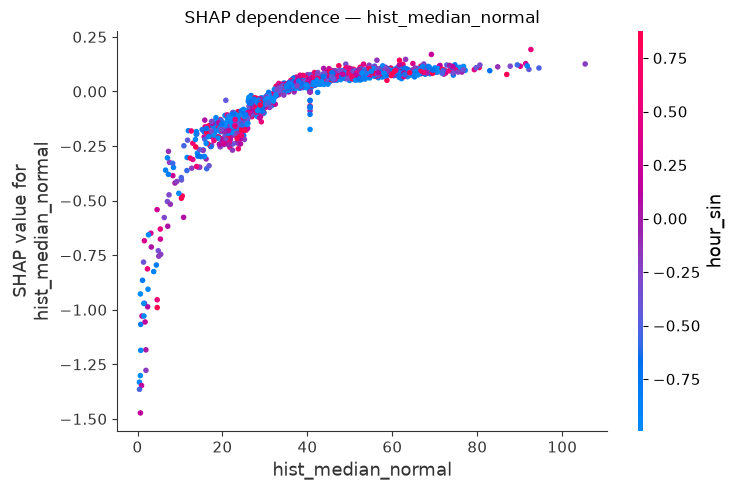

1. hist_median_normal


<Figure size 700x500 with 0 Axes>

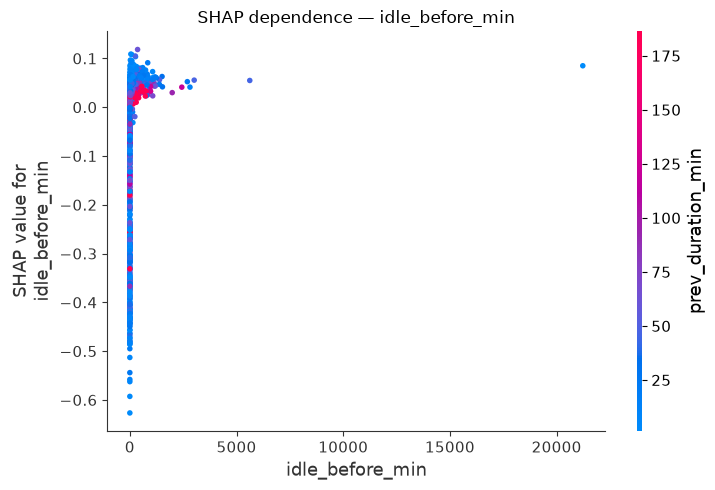

2. idle_before_min


<Figure size 700x500 with 0 Axes>

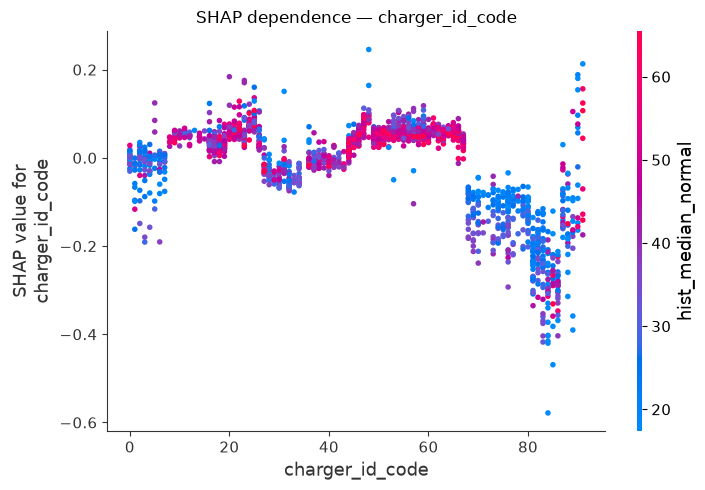

3. charger_id_code


In [48]:
print('TOP THREE DEPENDENCE PLOTS')
top3_features = global_importance.head(3)['feature'].tolist()
for rank, feature in enumerate(top3_features, start=1):
    plt.figure(figsize=(7, 5))
    shap.dependence_plot(feature, shap_values, X_sample, show=False)
    plt.title(f'SHAP dependence — {feature}')
    plt.tight_layout()
    plt.savefig(FIGURES / f'shap_dependence_{rank}_{feature}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()
    print(f"{rank}. {feature}")


Interpretation: each dependence plot displays the sampled feature values against their SHAP contribution; patterns describe model behavior, not causal effects.


### Local explanations for three real validation sessions
Choose a normal validation session under 20 minutes, one nearest the validation-normal median, and one over 120 minutes. Plot each with a SHAP waterfall.


LOCAL WATERFALL EXPLANATIONS
short    | true:     0.02 min | predicted:    14.75 min


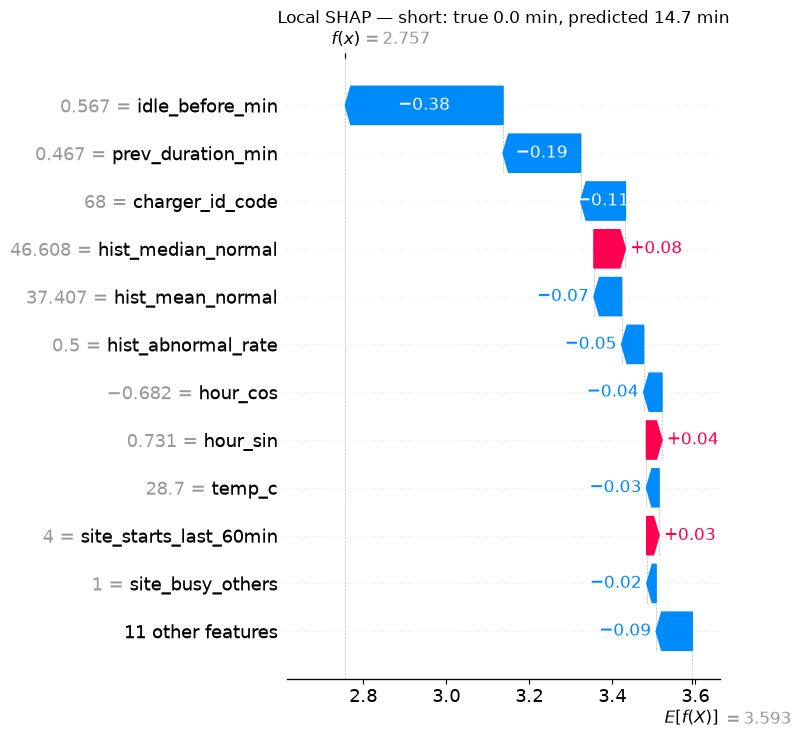

median   | true:    39.92 min | predicted:    54.24 min


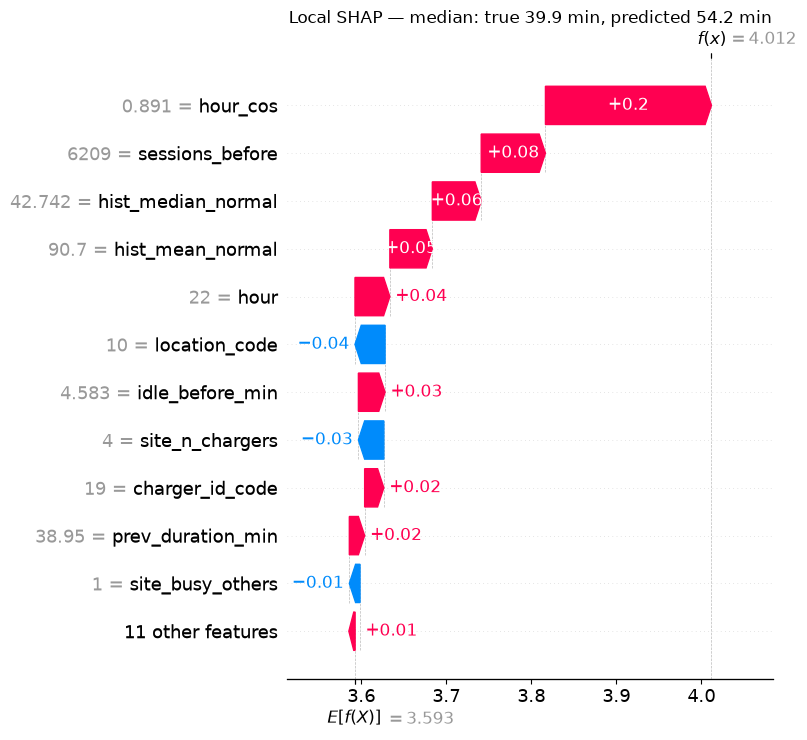

long     | true:  1402.85 min | predicted:    28.73 min


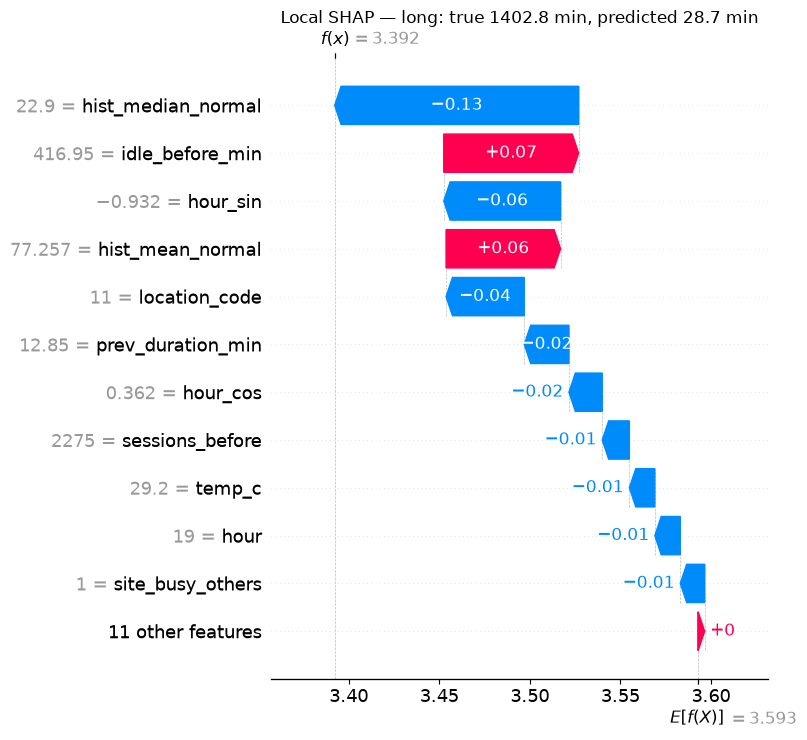

In [49]:
print('LOCAL WATERFALL EXPLANATIONS')
true_duration = validation_normal['target_min'].astype(float)
short_rows = validation_normal.loc[true_duration < 20]
long_rows = validation_normal.loc[true_duration > 120]
if short_rows.empty or long_rows.empty:
    raise ValueError('Validation normal rows do not contain both a <20 minute and >120 minute session.')
median_duration = float(true_duration.median())
selected = {
    'short': short_rows['target_min'].astype(float).idxmin(),
    'median': (true_duration - median_duration).abs().idxmin(),
    'long': long_rows['target_min'].astype(float).idxmax(),
}
selected_rows = validation_normal.loc[list(selected.values())]
X_local = encoder.transform(selected_rows)
local_margin = model.predict(X_local, output_margin=True)
local_pred_minutes = np.clip(np.expm1(local_margin), 0.0, float(bundle.get('duration_cap_min', bundle.get('CAP'))))
local_explanation = explainer(X_local)
local_shap = np.asarray(local_explanation.values)
local_base = np.asarray(local_explanation.base_values).reshape(-1)
for (label, row_index), position in zip(selected.items(), range(len(selected))):
    true_minutes = float(validation_normal.loc[row_index, 'target_min'])
    predicted_minutes = float(local_pred_minutes[position])
    print(f"{label:8s} | true: {true_minutes:8.2f} min | predicted: {predicted_minutes:8.2f} min")
    local_exp = shap.Explanation(values=local_shap[position], base_values=local_base[position], data=X_local.iloc[position].to_numpy(), feature_names=list(X_local.columns))
    shap.plots.waterfall(local_exp, max_display=12, show=False)
    plt.title(f'Local SHAP — {label}: true {true_minutes:.1f} min, predicted {predicted_minutes:.1f} min')
    plt.tight_layout()
    plt.savefig(FIGURES / f'shap_waterfall_{label}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()


Interpretation: the printed true/predicted minutes identify the selected cases. In each waterfall, positive contributions raise the log-minute output and negative contributions lower it relative to the base value.


### Group attribution view
Sum signed SHAP contributions within each feature group for each row, then average by group.


MEAN GROUP SHAP
calendar                     -0.00588027
weather                      -0.00243895
this charger's history        0.00089480
site state                    0.00843735
charger and location codes   -0.00889063


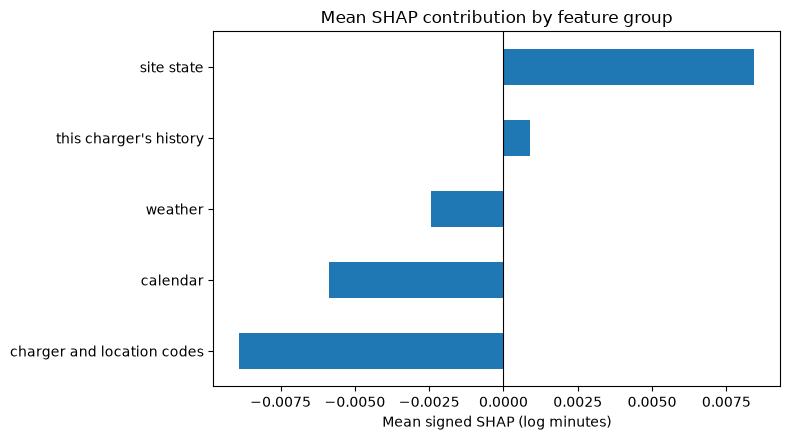

In [50]:
print('MEAN GROUP SHAP')
feature_groups = {
    'calendar': ['hour', 'dow', 'is_weekend', 'hour_sin', 'hour_cos'],
    'weather': ['temp_c', 'humidity', 'precip_mm'],
    "this charger's history": ['idle_before_min', 'prev_duration_min', 'hist_median_normal', 'hist_mean_normal', 'hist_abnormal_rate', 'sessions_before', 'has_history'],
    'site state': ['site_n_chargers', 'site_busy_others', 'site_busy_share', 'site_starts_last_60min'],
    'charger and location codes': ['charger_id_code', 'location_code', 'district_code'],
}
group_mean_shap = {}
for group, members in feature_groups.items():
    positions = [X_sample.columns.get_loc(feature) for feature in members if feature in X_sample.columns]
    group_mean_shap[group] = float(shap_values[:, positions].sum(axis=1).mean()) if positions else 0.0
group_table = pd.Series(group_mean_shap, name='mean_shap_log_minutes')
print(group_table.to_string(float_format=lambda value: f'{value:.8f}'))
plt.figure(figsize=(8, 4.5))
group_table.sort_values().plot(kind='barh')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Mean signed SHAP (log minutes)')
plt.title('Mean SHAP contribution by feature group')
plt.tight_layout()
plt.savefig(FIGURES / 'shap_group_mean.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close()


Interpretation: positive group means raise the model's log-minute output on average; negative group means lower it. Each group value sums its member-feature contributions before averaging.


## Limitations

SHAP values are in log minutes because the model target is `log1p(minutes)`. SHAP describes what the model relies on; it is not causal. `charger_id_code` is an integer category code treated as a number by the trees. Correlated features can share attribution credit.


In [51]:
print('## Final Summary')
print(f"Validation-normal SHAP sample: {sample_size} rows across {X_sample.shape[1]} features.")
print(f"Maximum additivity error: {additivity_error.max():.8g} log minutes; native-vs-SHAP maximum feature error: {native_error:.8g}.")
print('Top three global features:', ', '.join(top3_features))
print(f"Top-ten SHAP/gain Spearman correlation: {spearman:.6f}.")
print('Local validation sessions (true, predicted minutes):')
for (label, row_index), position in zip(selected.items(), range(len(selected))):
    print(f"  {label}: {float(validation_normal.loc[row_index, 'target_min']):.2f}, {float(local_pred_minutes[position]):.2f}")
print('Figures:', FIGURES)
print('Global table:', REPORTS / 'xai_global_importance.csv')


## Final Summary
Validation-normal SHAP sample: 2000 rows across 22 features.
Maximum additivity error: 3.5828853e-06 log minutes; native-vs-SHAP maximum feature error: 0.
Top three global features: hist_median_normal, idle_before_min, charger_id_code
Top-ten SHAP/gain Spearman correlation: 0.515152.
Local validation sessions (true, predicted minutes):
  short: 0.02, 14.75
  median: 39.92, 54.24
  long: 1402.85, 28.73
Figures: c:\Users\mariam\Desktop\SIC AI\ChargeSentinel-Twin\team\mariam_availability\notebooks\reports\figures\xai
Global table: c:\Users\mariam\Desktop\SIC AI\ChargeSentinel-Twin\team\mariam_availability\notebooks\reports\xai_global_importance.csv
